# Regression losses

Setting: 
* true values $y_1^*,\ldots, y_N^*$
* predictions $y_1,\ldots, y_N$

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import HuberRegressor

rng=np.random.default_rng()


## Outliers

**Mean square loss**
$$
\frac{1}{N}\sum_{i=1}^N(y_i^*-y_i)^2
$$

In many dimensions
$$
\frac{1}{N}\sum_{i=1}^N ||y_i^*-y_i||_2^2
$$

(0.0, 23.185222700854936)

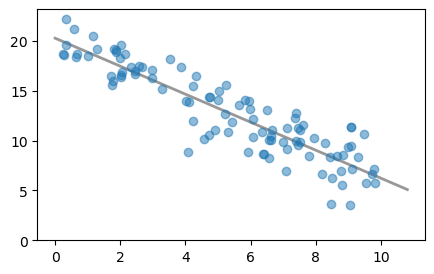

In [50]:
N=100
xx=10*rng.random(size=N)
errors=rng.normal(size=N)*2
yy=-1.3*xx+20+errors

linreg=LinearRegression()
linreg.fit(xx.reshape(-1,1),yy)
a,b=linreg.coef_[0],linreg.intercept_
fitfun=lambda x: a*x+b
fitxx=np.array([0,max(xx)*1.1])
 
fig,ax=plt.subplots(figsize=(5,3))
ax.scatter(xx,yy,alpha=0.5,zorder=10)
ax.plot(fitxx,fitfun(fitxx),linewidth=2,color="tab:grey",alpha=0.8,label="mse fit")
ax.set_ylim(bottom=0)
ax.legend()
plt.show()

**Mean absolute error (MAE)** 

$$
\frac{1}{N}\sum_{i=1}^N|y_i^*-y_i|
$$

Multidimensional analog is not $||\cdot ||_1$-norm but
$$
\frac{1}{N}\sum_{i=1}^N ||y_i^*-y_i||_2
$$
(ie, no squaring)

**Huber loss**

Huber function 
$$
h:\mathbb R\to\mathbb R,\quad x\mapsto \begin{cases}
x^2 &\text{ for }x\leq\delta\\
2\delta |x|-\delta^2&\text{ for }x>\delta
\end{cases} 
$$
or in $\mathbb R^n$
$$
h:\mathbb R^n\to\mathbb R,\quad x\mapsto \begin{cases}
||x||_2^2 &\text{ for }||x||_2\leq\delta\\
2\delta||x||_2-\delta^2&\text{ for }||x||_2>\delta
\end{cases} 
$$

Then we minimise
$$
\frac{1}{N}\sum_{i=1}^N h(y_i^*-y_i)
$$

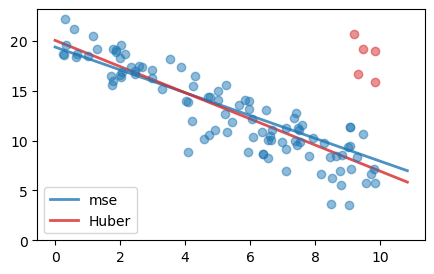

In [69]:
# add outliers
K=5
outlier_x=rng.random(size=K)+9
outlier_errors=rng.normal(size=K)*2
outlier_y=-0.5*outlier_x+25+outlier_errors

xx2=np.concat([xx,outlier_x])
yy2=np.concat([yy,outlier_y])

linreg=LinearRegression()
linreg.fit(xx2.reshape(-1,1),yy2)
a,b=linreg.coef_[0],linreg.intercept_
fitfun=lambda x: a*x+b

huber=HuberRegressor(epsilon=1)
huber.fit(xx2.reshape(-1,1),yy2)
ah,bh=huber.coef_[0],huber.intercept_
huberfit=lambda x: ah*x+bh

fitxx=np.array([0,max(xx2)*1.1])

fig,ax=plt.subplots(figsize=(5,3))
ax.scatter(xx,yy,alpha=0.5,zorder=10)
ax.scatter(outlier_x,outlier_y,alpha=0.5,zorder=10,color="tab:red")
ax.plot(fitxx,fitfun(fitxx),linewidth=2,color="tab:blue",alpha=0.8,label="mse")
ax.plot(fitxx,huberfit(fitxx),linewidth=2,color="tab:red",alpha=0.8,label="Huber")
ax.set_ylim(bottom=0)
ax.legend()

## data at different scales

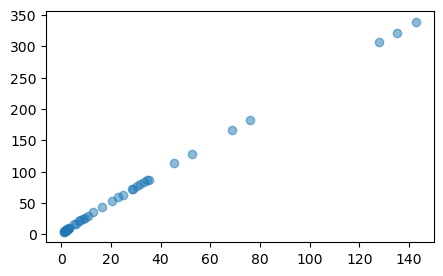

In [2]:
N=40
xx=np.exp(5*rng.random(size=N))
errors=rng.normal(size=N)*xx/50
yy=2.3*xx+errors+np.log(xx+1)*2

fig,ax=plt.subplots(figsize=(5,3))
ax.scatter(xx,yy,alpha=0.5)

In [3]:
def show_small_large(xx,yy,fitfun,ab=None,k=10):
    fitxx=np.array([0,max(xx)*1.1])
    
    fig,axs=plt.subplots(1,3,figsize=(12,3))
    axs[0].scatter(xx,yy,alpha=0.5,zorder=10)
    axs[0].plot(fitxx,fitfun(fitxx),linewidth=2,alpha=0.5,color="tab:grey")
    if ab is not None:
        axs[0].set_title("whole range, a={:.2f} b={:.2f}".format(ab[0],ab[1]))
    else:    
        axs[0].set_title("whole range")
    
    axs[1].scatter(xx,yy,alpha=0.5,zorder=10)
    xright=1.2*sorted(xx)[k-1]
    ytop=1.2*(a*xright+b)
    axs[1].plot(fitxx,fitfun(fitxx),linewidth=2,alpha=0.5,color="tab:grey")
    axs[1].set_xlim(-0.05,xright)
    axs[1].set_ylim(-0.05,ytop)
    axs[1].set_title("small range")
    
    xright=1.2*np.max(xx)
    xleft=0.9*sorted(xx)[-k]
    ytop=1.1*(a*xright+b)
    ybottom=0.9*(a*xleft+b)
    axs[2].scatter(xx,yy,alpha=0.5,zorder=10)
    axs[2].plot(fitxx,fitfun(fitxx),linewidth=2,alpha=0.5,color="tab:grey")
    axs[2].set_xlim(xleft,xright)
    axs[2].set_ylim(ybottom,ytop)
    axs[2].set_title("large range")


### mean square error

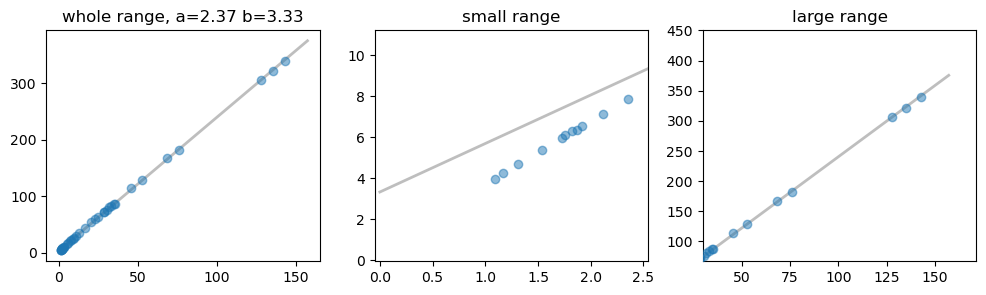

In [4]:
linreg=LinearRegression()
linreg.fit(xx.reshape(-1,1),yy)
a,b=linreg.coef_[0],linreg.intercept_

fitfun=lambda x:a*x+b
show_small_large(xx,yy,fitfun,ab=(a,b))

### mean squared log error

**Mean squared log error**
$$
\frac{1}{N}\sum_{i=1}^N (\log(y_i^*+1)-\log(y_i+1))^2
$$

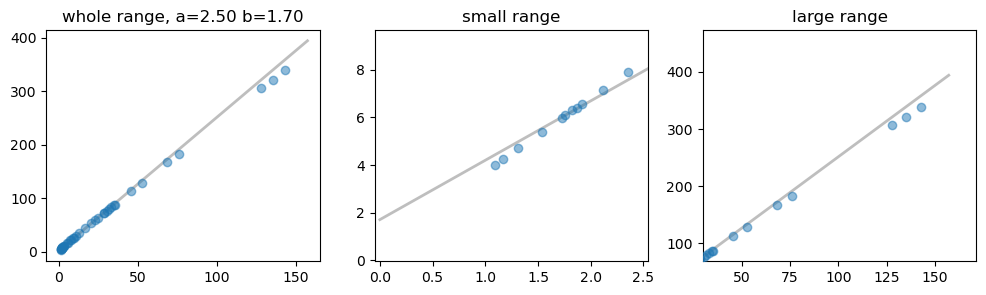

In [5]:
import scipy as sp
from scipy.optimize import curve_fit

def ansatzfun(x,a,b):
    return np.log(a*x+b+1)

popt, pcov = curve_fit(ansatzfun, xx, np.log(yy+1),bounds=(0,np.inf))
a,b=popt

fitfun=lambda x: a*x+b

show_small_large(xx,yy,fitfun,ab=popt)

### mean absolute percentage error

**mean absolute percentage error (MAPE)**
$$
\frac{1}{N}\sum_{i=1}^N \frac{|y_i^*-y_i|}{y_i^*}
$$
Technically, we'd need to multiply with 100% to obtain percentages.

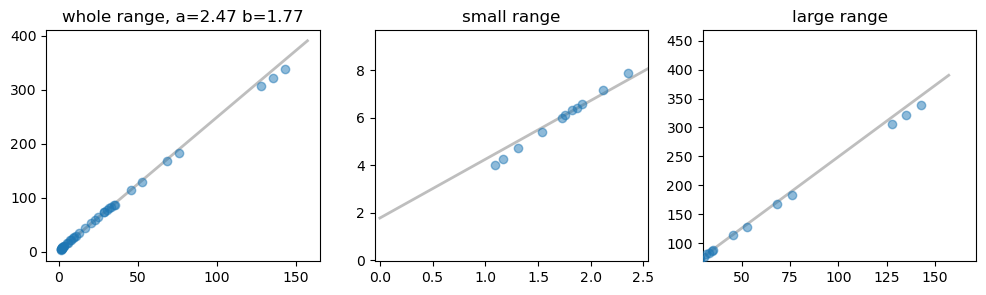

In [6]:
from scipy.optimize import minimize

def make_obj_fun(xx,yy):
    def obj_fun(vals):
        a,b=vals
        return np.mean(np.abs(a*xx+b-yy)/yy)
    return obj_fun

obj_fun=make_obj_fun(xx,yy)
initial=np.array([2,0])
res = minimize(obj_fun, initial,tol=1e-6,method='Nelder-Mead')

a,b=res.x
fitfun=lambda x: a*x+b
show_small_large(xx,yy,fitfun,ab=res.x)

## MAPE can become large if $y_\text{true}$ small

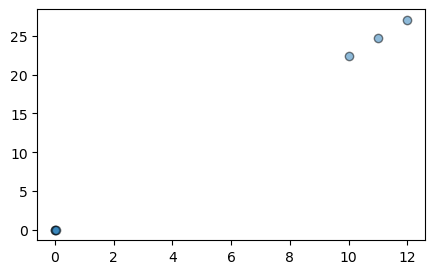

In [39]:
xx=np.array([0.01,0.02,0.03,10,11,12])
yy=np.where(xx<=2,np.log(xx+1),2.34*xx-1)

fig,ax=plt.subplots(figsize=(5,3))
ax.scatter(xx,yy,alpha=0.5,edgecolor="k")

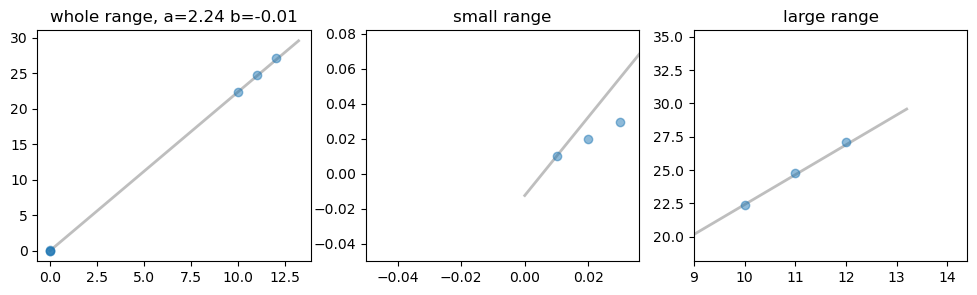

In [31]:
obj_fun=make_obj_fun(xx,yy)
initial=np.array([2,0])
res = minimize(obj_fun, initial,tol=1e-6,method='Nelder-Mead')

a,b=res.x
fitfun=lambda x: a*x+b
show_small_large(xx,yy,fitfun,ab=res.x,k=3)

In [32]:
def mape(y_true,y_pred):
    return np.abs(y_true-y_pred)/y_true

mape(yy,fitfun(xx))*100,np.mean(mape(yy,fitfun(xx))*100)

(array([6.71208584e-06, 6.34267719e+01, 8.53094625e+01, 3.94792446e-06,
        3.99162547e-01, 7.29344581e-01]),
 np.float64(24.97745869259202))

$$
\frac{1}{N}\sum_{i=1}^N \frac{|y_i^*-y_i|}{y_i^*+\epsilon}
$$


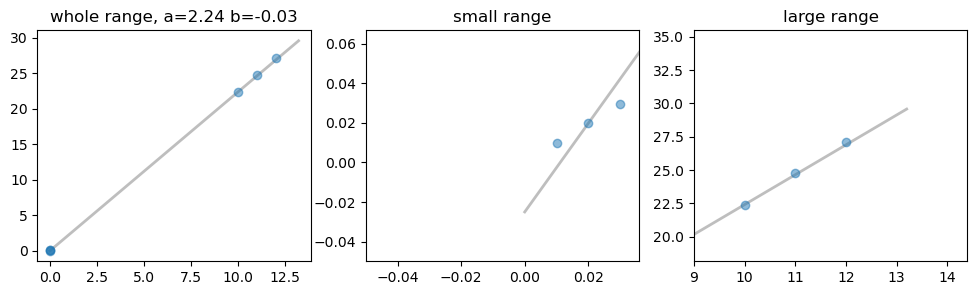

In [36]:
def make_obj_fun2(xx,yy,eps):
    def obj_fun(vals):
        a,b=vals
        return np.mean(np.abs(a*xx+b-yy)/(yy+eps))
    return obj_fun

obj_fun=make_obj_fun2(xx,yy,eps=0.02)
initial=np.array([2,0])
res = minimize(obj_fun, initial,tol=1e-6,method='Nelder-Mead')

a,b=res.x
fitfun=lambda x: a*x+b
show_small_large(xx,yy,fitfun,ab=res.x,k=3)